# BCSE209P Machine Learning-(FALL 2026) Laboratory Template

## SCOPE, VIT Chennai

### Student Information

- **Student Name:** Shrri Dharshan D R
- **Register Number:** 23BPS1090
- **Course Code:** BCSE209P
- **Course Title:** Machine Learning Laboratory
- **Faculty:** Dr. S. Shridevi
- **Experiment No.:** 8
- **Date:** 16.09.2026

---

In [1]:
# Student Identification

AUTHOR        = "Shrri Dharshan D R"
REGISTER_NO   = "23BPS1090"
COURSE        = "BCSE209P-Machine Learning Laboratory"
FACULTY       = "Dr. S. Shridevi"
INSTITUTION   = "SCOPE, VIT Chennai"
NOTEBOOK_ID   = "ML-LAB-08"

print("Notebook Loaded Successfully")

Notebook Loaded Successfully


In [2]:
# Notebook Fingerprint

import hashlib
import datetime

fingerprint = hashlib.sha256(
    (AUTHOR + REGISTER_NO + COURSE + NOTEBOOK_ID +
     str(datetime.datetime.now())).encode()
).hexdigest()

print("Notebook Fingerprint:")
print(fingerprint)

Notebook Fingerprint:
f105a62ce9d4a698ecdaff283d7a330e97bebfb44872178bec1f32f71e4bd925


# Experiment Details

## Objective

To implement and compare multiple **Ensemble Learning** methods — Bagging (Random Forest),
Boosting (AdaBoost, Gradient Boosting, XGBoost), and Voting — using the
*Bank Marketing Dataset* (UCI ML Repository, ID: 222),
in order to predict whether a client will subscribe to a term deposit (`yes`/`no`),
and to evaluate each ensemble against standard classification metrics
(Accuracy, Precision, Recall, F1-Score, ROC-AUC) along with feature importance
analysis and ensemble comparison visualisations.

---

## Theory

**Ensemble Learning** combines multiple base learners to produce a model whose
predictive performance exceeds any individual component. The core idea is that
diverse, weakly-correlated models make different errors; combining their predictions
reduces the overall error.

### Bias–Variance Decomposition

For any model, the expected generalisation error decomposes as:

$$\text{MSE} = \text{Bias}^2 + \text{Variance} + \text{Irreducible Noise}$$

- **Bagging** targets high-variance models (deep trees): training on bootstrap samples
  and averaging reduces variance with minimal effect on bias.
- **Boosting** targets high-bias models (shallow trees): sequentially correcting errors
  reduces bias, though it can increase variance if over-iterated.

### 1. Bagging — Bootstrap Aggregating

Each of $B$ base learners $h_b$ is trained on a bootstrap sample
$\mathcal{D}_b \sim \mathcal{D}$ (sample with replacement).
The ensemble prediction averages (regression) or takes a majority vote (classification):

$$H(\mathbf{x}) = \text{majority-vote}\{h_1(\mathbf{x}),\, h_2(\mathbf{x}),\, \ldots,\, h_B(\mathbf{x})\}$$

**Random Forest** extends Bagging: at each split, only a random subset of
$m \leq p$ features is considered, decorrelating the trees further.

### 2. AdaBoost — Adaptive Boosting

Each weak learner $h_t$ is trained on a reweighted dataset where misclassified
examples from round $t-1$ receive higher weight $w_i$. The final classifier is:

$$H(\mathbf{x}) = \text{sign}\!\left(\sum_{t=1}^{T} \alpha_t\, h_t(\mathbf{x})\right)$$

where the stage weight $\alpha_t = \frac{1}{2}\ln\!\left(\frac{1-\epsilon_t}{\epsilon_t}\right)$
and $\epsilon_t$ is the weighted error of $h_t$.

### 3. Gradient Boosting

A functional gradient-descent view: at each step $m$, fit a tree to the
**negative gradient** (pseudo-residuals) of a differentiable loss $\mathcal{L}$:

$$F_m(\mathbf{x}) = F_{m-1}(\mathbf{x}) + \nu \cdot h_m(\mathbf{x})$$

where $\nu$ is the learning rate (shrinkage). For log-loss (binary cross-entropy)
the pseudo-residuals are $r_i = y_i - p_i$.

### 4. XGBoost

Adds second-order Taylor expansion of the loss, $L_1/L_2$ regularisation on leaf
weights, and column/row subsampling to standard Gradient Boosting:

$$\tilde{\mathcal{L}} = \sum_i \left[g_i f_t(\mathbf{x}_i) + \tfrac{1}{2}h_i f_t(\mathbf{x}_i)^2\right] + \Omega(f_t)$$

where $g_i = \partial_{\hat y}\ell$, $h_i = \partial_{\hat y}^2\ell$, and
$\Omega(f) = \gamma T + \frac{1}{2}\lambda\|\mathbf{w}\|^2$.

### 5. Voting Ensemble

Combines heterogeneous classifiers. **Soft voting** averages predicted class
probabilities before taking `argmax`, leveraging calibrated confidence:

$$H(\mathbf{x}) = \arg\max_k \sum_{j=1}^{M} p_{jk}(\mathbf{x})$$

### Evaluation Metrics

| Metric | Formula |
|--------|---------|
| Accuracy | $\dfrac{TP + TN}{TP + TN + FP + FN}$ |
| Precision | $\dfrac{TP}{TP + FP}$ |
| Recall (Sensitivity) | $\dfrac{TP}{TP + FN}$ |
| F1-Score | $2 \cdot \dfrac{P \cdot R}{P + R}$ |
| ROC-AUC | Area under the Receiver Operating Characteristic curve |

---

## Dataset

- **Name:** Bank Marketing Dataset
- **Source:** UCI Machine Learning Repository (ID: 222)  
  — https://archive.ics.uci.edu/dataset/222/bank+marketing
- **Total Instances:** 45,211 client contact records
- **Features (16):** Client demographics, last contact details, campaign information,
  and socio-economic indicators (age, job, marital, education, default, balance,
  housing, loan, contact, day, month, duration, campaign, pdays, previous, poutcome)
- **Target:** `y` — `yes` = subscribed to term deposit, `no` = did not subscribe
- **Class Distribution:** ~88 % No, ~12 % Yes (imbalanced)
- **Missing Values:** Some features encoded as `"unknown"` (treated as a category)
- **File Format:** CSV with semicolon delimiter (`bank-full.csv`)
- **Task Type:** Binary Classification
- **Licence:** CC BY 4.0

In [3]:
# Step 1 — Install and import required libraries

# Uncomment the line below if xgboost is not yet installed:
# !pip install xgboost --quiet

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import os, zipfile, urllib.request

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, auc,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)

from xgboost import XGBClassifier

pd.set_option("display.max_columns", None)
print("All libraries imported successfully.")

All libraries imported successfully.


In [4]:
# Step 2 — Download and load the UCI Bank Marketing dataset (ID: 222)

DATA_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
DATA_DIR = "bank_marketing_data"
os.makedirs(DATA_DIR, exist_ok=True)

zip_path = os.path.join(DATA_DIR, "dataset.zip")
if not os.path.exists(zip_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, zip_path)
    print("Download complete.")
else:
    print("Dataset archive already present.")

# Inspect zip contents
with zipfile.ZipFile(zip_path) as zf:
    print("Top-level zip contents:", zf.namelist())
    zf.extractall(DATA_DIR)

# The archive contains a nested zip — extract bank-full.csv
inner_zip = os.path.join(DATA_DIR, "bank.zip")
if os.path.exists(inner_zip):
    with zipfile.ZipFile(inner_zip) as zf2:
        print("Inner zip contents:", zf2.namelist())
        zf2.extractall(DATA_DIR)

csv_path = os.path.join(DATA_DIR, "bank-full.csv")
df_raw = pd.read_csv(csv_path, sep=";")

print("\nDataset loaded successfully.")
print("Shape:", df_raw.shape)
print(df_raw.head())

Download complete.
Top-level zip contents: ['bank.zip', 'bank-additional.zip']
Inner zip contents: ['bank-full.csv', 'bank-names.txt', 'bank.csv']

Dataset loaded successfully.
Shape: (45211, 17)
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unk

In [5]:
# Step 3 — Dataset overview

print("Dataset  : Bank Marketing")
print("Samples  :", df_raw.shape[0])
print("Columns  :", df_raw.shape[1])
print("Source   : UCI ML Repository (ID: 222)")
print("Target   : y (yes = subscribed, no = did not subscribe)")

Dataset  : Bank Marketing
Samples  : 45211
Columns  : 17
Source   : UCI ML Repository (ID: 222)
Target   : y (yes = subscribed, no = did not subscribe)


In [6]:
# Step 4 — Explore dataset structure

print("Shape:", df_raw.shape)
print("\nColumn names:", df_raw.columns.tolist())
print("\nFirst 10 rows:")
print(df_raw.head(10))

Shape: (45211, 17)

Column names: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

First 10 rows:
   age           job   marital  education default  balance housing loan  \
0   58    management   married   tertiary      no     2143     yes   no   
1   44    technician    single  secondary      no       29     yes   no   
2   33  entrepreneur   married  secondary      no        2     yes  yes   
3   47   blue-collar   married    unknown      no     1506     yes   no   
4   33       unknown    single    unknown      no        1      no   no   
5   35    management   married   tertiary      no      231     yes   no   
6   28    management    single   tertiary      no      447     yes  yes   
7   42  entrepreneur  divorced   tertiary     yes        2     yes   no   
8   58       retired   married    primary      no      121     yes   no   
9   43    technician    single 

In [7]:
# Step 5 — Data types and unique value counts

print("Dataset Info:")
df_raw.info()
print("\nData Types:")
print(df_raw.dtypes)
print("\nUnique Values per Column:")
print(df_raw.nunique())

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB

Data Types:
age          int64
job            str
marital        str
education      str
default        str
balance    

In [8]:
# Step 6 — Check for missing values and duplicates

missing = df_raw.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "No missing values found.")
print("\nTotal missing values:", df_raw.isnull().sum().sum())
print("\nDuplicate records   :", df_raw.duplicated().sum())
print("\nNote: 'unknown' category values exist in some columns (job, education, etc.)")
for col in df_raw.select_dtypes(include="object").columns:
    unk = (df_raw[col] == "unknown").sum()
    if unk > 0:
        print(f"  {col}: {unk} 'unknown' entries")

Missing values per column:
No missing values found.

Total missing values: 0

Duplicate records   : 0

Note: 'unknown' category values exist in some columns (job, education, etc.)
  job: 288 'unknown' entries
  education: 1857 'unknown' entries
  contact: 13020 'unknown' entries
  poutcome: 36959 'unknown' entries


C:\Users\shrri\AppData\Local\Temp\ipykernel_13768\3979847321.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_raw.select_dtypes(include="object").columns:


Target variable distribution (y):
y
no     39922
yes     5289
Name: count, dtype: int64

Class proportions (%):
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


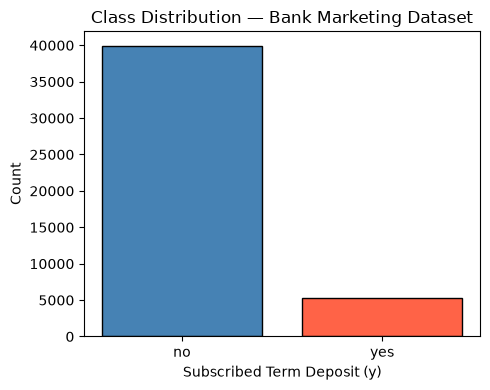

In [9]:
# Step 7 — Target class distribution

print("Target variable distribution (y):")
print(df_raw["y"].value_counts())
print("\nClass proportions (%):")
print(round(df_raw["y"].value_counts(normalize=True) * 100, 2))

plt.figure(figsize=(5, 4))
counts = df_raw["y"].value_counts()
plt.bar(counts.index, counts.values,
        color=["steelblue", "tomato"], edgecolor="black")
plt.title("Class Distribution — Bank Marketing Dataset")
plt.xlabel("Subscribed Term Deposit (y)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [10]:
# Step 8 — Statistical summary

print("Statistical Summary (numeric features):")
print(df_raw.describe())

Statistical Summary (numeric features):
                age        balance           day      duration      campaign  \
count  45211.000000   45211.000000  45211.000000  45211.000000  45211.000000   
mean      40.936210    1362.272058     15.806419    258.163080      2.763841   
std       10.618762    3044.765829      8.322476    257.527812      3.098021   
min       18.000000   -8019.000000      1.000000      0.000000      1.000000   
25%       33.000000      72.000000      8.000000    103.000000      1.000000   
50%       39.000000     448.000000     16.000000    180.000000      2.000000   
75%       48.000000    1428.000000     21.000000    319.000000      3.000000   
max       95.000000  102127.000000     31.000000   4918.000000     63.000000   

              pdays      previous  
count  45211.000000  45211.000000  
mean      40.197828      0.580323  
std      100.128746      2.303441  
min       -1.000000      0.000000  
25%       -1.000000      0.000000  
50%       -1.000000    

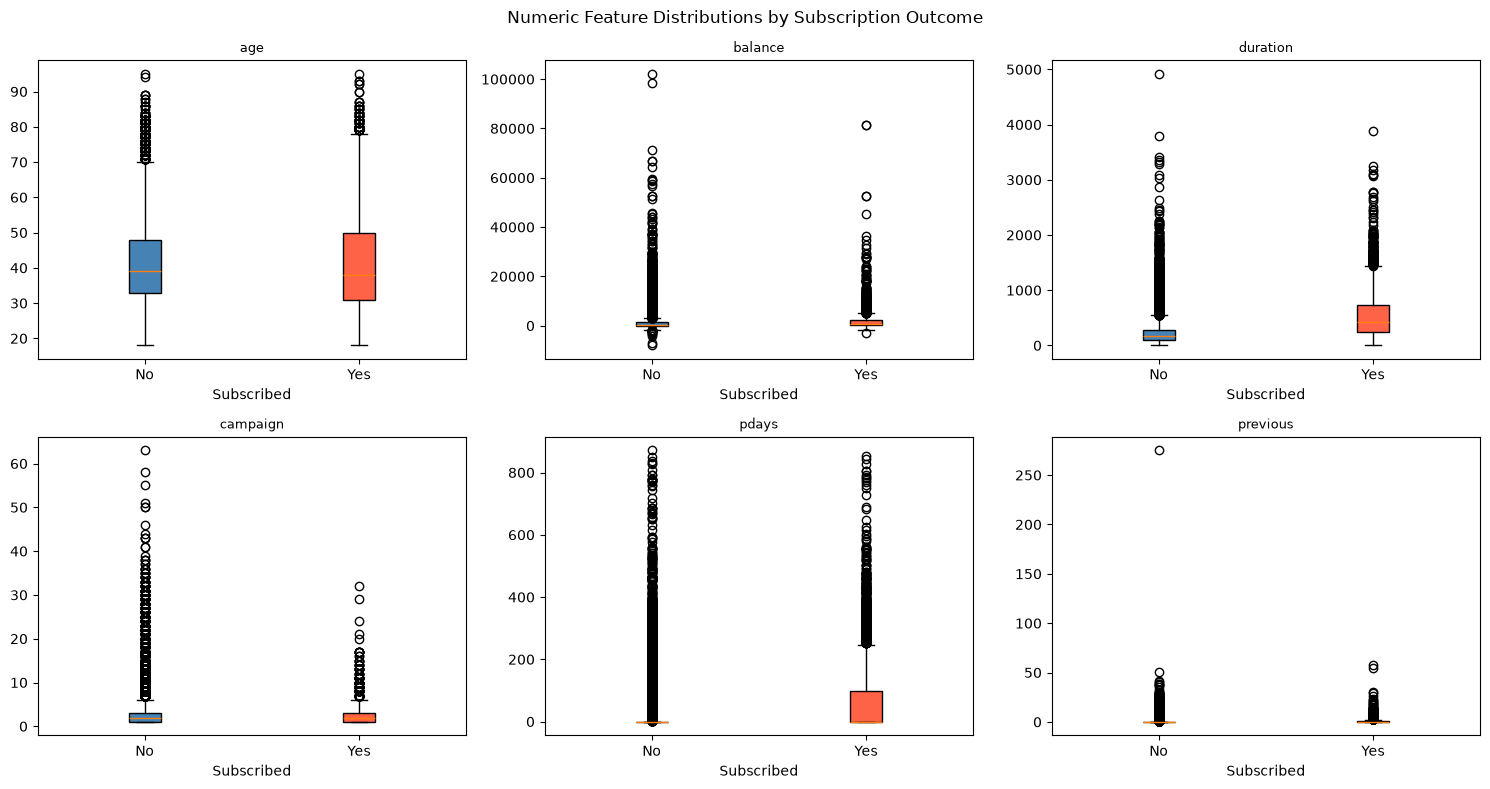

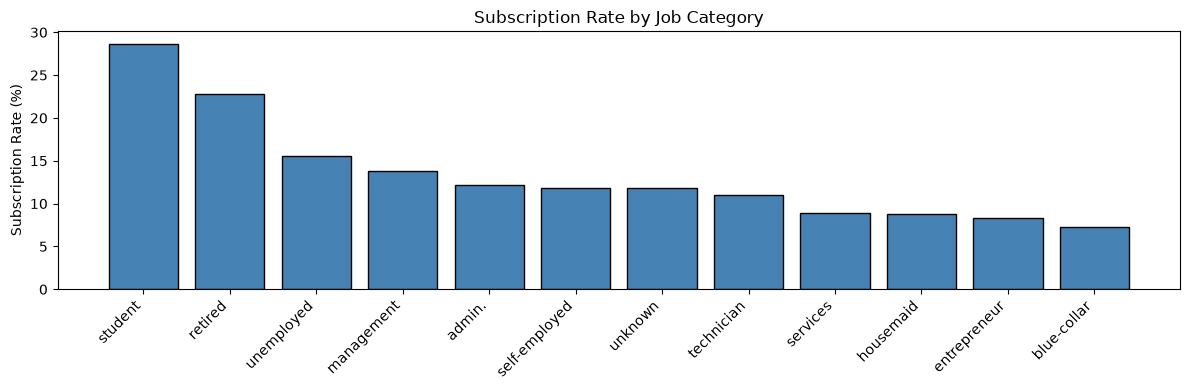

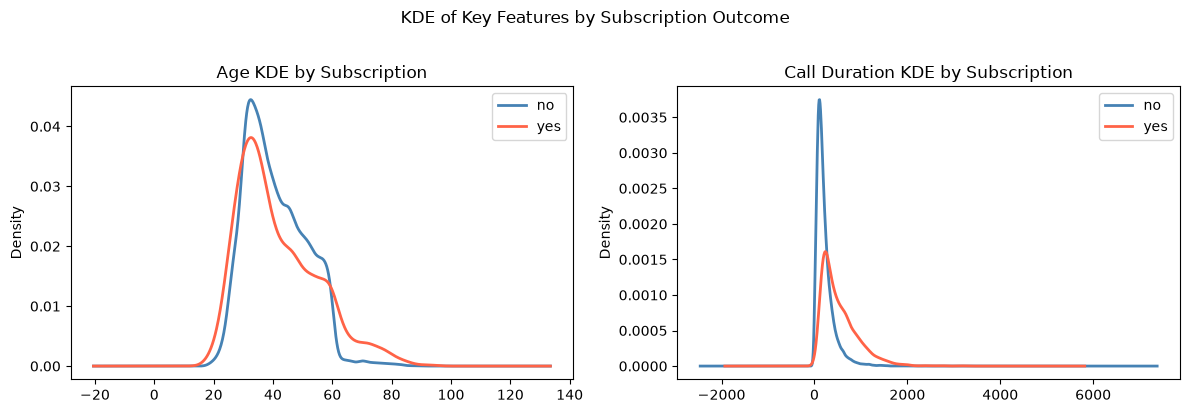

In [11]:
# Step 9 — Exploratory Data Analysis

numeric_cols = ["age", "balance", "duration", "campaign", "pdays", "previous"]

# 9a. Box plots — numeric features by subscription outcome
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    data_by_class = [df_raw[df_raw["y"] == k][col].values for k in ["no", "yes"]]
    bp = axes[i].boxplot(data_by_class, tick_labels=["No", "Yes"], patch_artist=True)
    for patch, c in zip(bp["boxes"], ["steelblue", "tomato"]):
        patch.set_facecolor(c)
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel("Subscribed")
plt.suptitle("Numeric Feature Distributions by Subscription Outcome")
plt.tight_layout()
plt.show()

# 9b. Categorical feature: job vs subscription rate
plt.figure(figsize=(12, 4))
job_sub = df_raw.groupby("job")["y"].apply(lambda x: (x == "yes").mean() * 100).sort_values(ascending=False)
plt.bar(job_sub.index, job_sub.values, color="steelblue", edgecolor="black")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Subscription Rate (%)")
plt.title("Subscription Rate by Job Category")
plt.tight_layout()
plt.show()

# 9c. KDE — age and duration by subscription
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for k, colour in [("no", "steelblue"), ("yes", "tomato")]:
    df_raw[df_raw["y"] == k]["age"].plot.kde(
        ax=axes[0], label=k, color=colour, lw=2)
    df_raw[df_raw["y"] == k]["duration"].plot.kde(
        ax=axes[1], label=k, color=colour, lw=2)
axes[0].set_title("Age KDE by Subscription")
axes[0].legend()
axes[1].set_title("Call Duration KDE by Subscription")
axes[1].legend()
plt.suptitle("KDE of Key Features by Subscription Outcome", y=1.02)
plt.tight_layout()
plt.show()

In [12]:
# Step 10 — Preprocessing: encode categorical features

df = df_raw.drop_duplicates().copy()

# Label-encode all object columns
le = LabelEncoder()
categorical_cols = df.select_dtypes(include="object").columns.tolist()
print("Categorical columns to encode:", categorical_cols)

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

# Target: 'y' is now 0 (no) / 1 (yes)
print("\nEncoding complete.")
print("Target mapping: 0 = no, 1 = yes")
print("\nFirst 5 rows after encoding:")
print(df.head())
print("\nTarget distribution after encoding:")
print(df["y"].value_counts())

Categorical columns to encode: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

Encoding complete.
Target mapping: 0 = no, 1 = yes

First 5 rows after encoding:
   age  job  marital  education  default  balance  housing  loan  contact  \
0   58    4        1          2        0     2143        1     0        2   
1   44    9        2          1        0       29        1     0        2   
2   33    2        1          1        0        2        1     1        2   
3   47    1        1          3        0     1506        1     0        2   
4   33   11        2          3        0        1        0     0        2   

   day  month  duration  campaign  pdays  previous  poutcome  y  
0    5      8       261         1     -1         0         3  0  
1    5      8       151         1     -1         0         3  0  
2    5      8        76         1     -1         0         3  0  
3    5      8        92         1     -1         0         3 

C:\Users\shrri\AppData\Local\Temp\ipykernel_13768\20647318.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


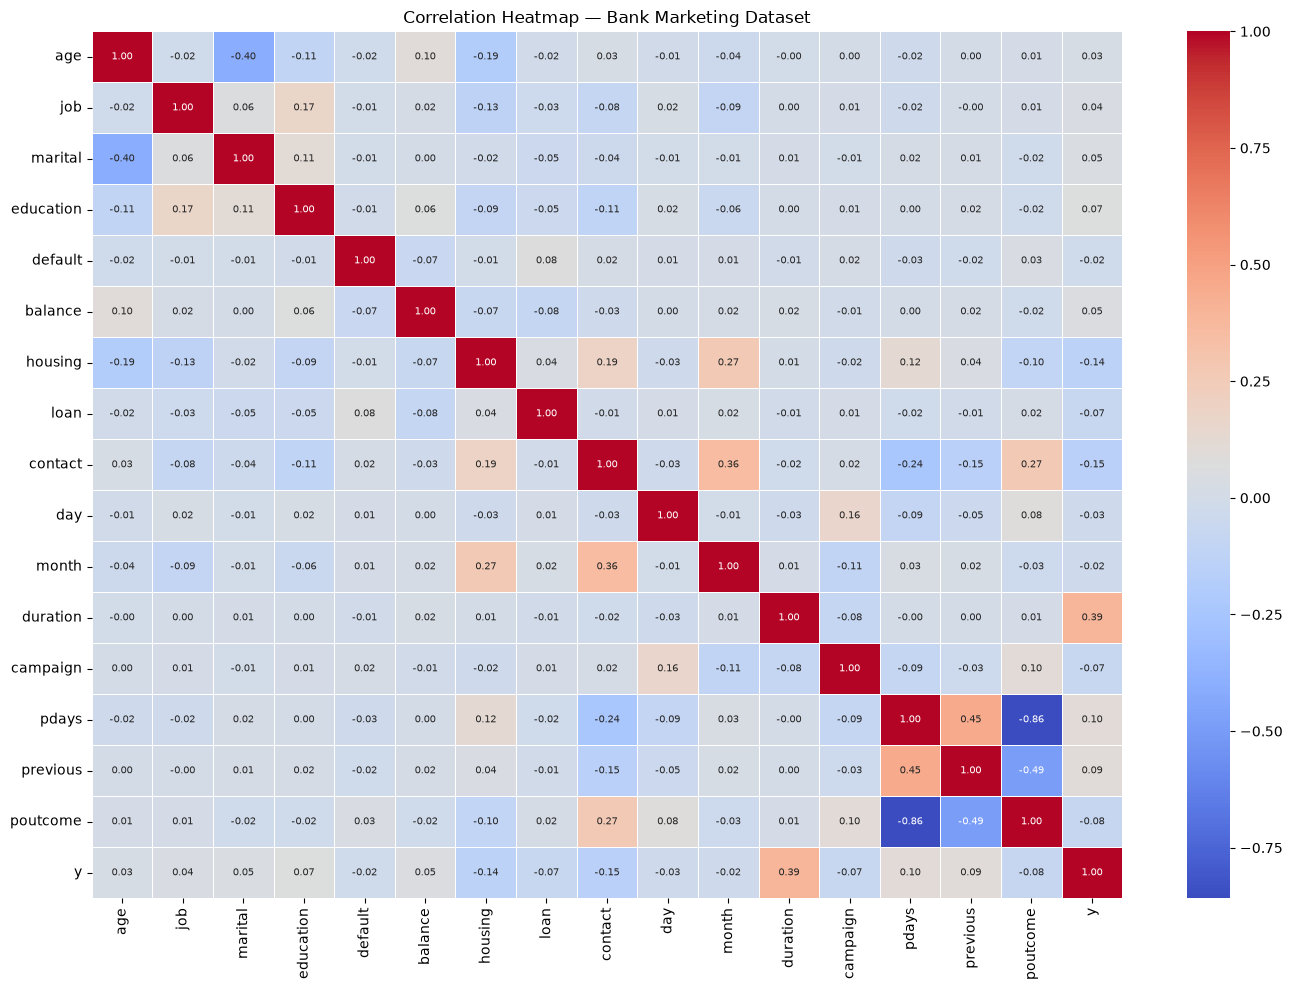


Features by |correlation| with target y (descending):
duration     0.394521
contact      0.148395
housing      0.139173
pdays        0.103621
previous     0.093236
poutcome     0.077840
campaign     0.073172
loan         0.068185
education    0.066241
balance      0.052838
marital      0.045588
job          0.040438
day          0.028348
age          0.025155
month        0.024471
default      0.022419
Name: y, dtype: float64


In [13]:
# Step 11 — Correlation heatmap

plt.figure(figsize=(14, 10))
sns.heatmap(
    df.corr(),
    cmap="coolwarm", annot=True, fmt=".2f", linewidths=0.5, annot_kws={"size": 7}
)
plt.title("Correlation Heatmap — Bank Marketing Dataset")
plt.tight_layout()
plt.show()

target_corr = df.corr()["y"].drop("y").abs().sort_values(ascending=False)
print("\nFeatures by |correlation| with target y (descending):")
print(target_corr)

In [14]:
# Step 12 — Feature / target split and train-test split

X = df.drop("y", axis=1)
y = df["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set size :", X_train.shape)
print("Test set size     :", X_test.shape)
print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts())
print("\nTest class distribution:")
print(pd.Series(y_test).value_counts())

Training set size : (36168, 16)
Test set size     : (9043, 16)

Training class distribution:
y
0    31937
1     4231
Name: count, dtype: int64

Test class distribution:
y
0    7985
1    1058
Name: count, dtype: int64


In [15]:
# Step 13 — Feature Scaling (StandardScaler)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print("Feature scaling completed.")
print("Mean of first feature (train, after scaling):", round(X_train_sc[:, 0].mean(), 6))
print("Std  of first feature (train, after scaling):", round(X_train_sc[:, 0].std(),  6))

Feature scaling completed.
Mean of first feature (train, after scaling): -0.0
Std  of first feature (train, after scaling): 1.0


In [16]:
# Step 14 — Train Ensemble Models

# ── 14a. Random Forest (Bagging) ──────────────────────────────────────────
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_sc, y_train)
rf_pred = rf.predict(X_test_sc)
rf_prob = rf.predict_proba(X_test_sc)[:, 1]
print("Random Forest trained. Estimators:", rf.n_estimators)

# ── 14b. Bagging (Decision Tree base) ────────────────────────────────────
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(), n_estimators=150, random_state=42, n_jobs=-1)
bag.fit(X_train_sc, y_train)
bag_pred = bag.predict(X_test_sc)
bag_prob = bag.predict_proba(X_test_sc)[:, 1]
print("Bagging trained. Estimators:", bag.n_estimators)

# ── 14c. AdaBoost ────────────────────────────────────────────────────────
ada = AdaBoostClassifier(n_estimators=150, learning_rate=0.1, random_state=42)
ada.fit(X_train_sc, y_train)
ada_pred = ada.predict(X_test_sc)
ada_prob = ada.predict_proba(X_test_sc)[:, 1]
print("AdaBoost trained. Estimators:", ada.n_estimators)

# ── 14d. Gradient Boosting ───────────────────────────────────────────────
gb = GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, random_state=42)
gb.fit(X_train_sc, y_train)
gb_pred = gb.predict(X_test_sc)
gb_prob = gb.predict_proba(X_test_sc)[:, 1]
print("Gradient Boosting trained. Estimators:", gb.n_estimators)

# ── 14e. XGBoost ─────────────────────────────────────────────────────────
xgb = XGBClassifier(
    n_estimators=200, learning_rate=0.05, max_depth=6,
    eval_metric="logloss", random_state=42, use_label_encoder=False)
xgb.fit(X_train_sc, y_train)
xgb_pred = xgb.predict(X_test_sc)
xgb_prob = xgb.predict_proba(X_test_sc)[:, 1]
print("XGBoost trained. Estimators:", xgb.n_estimators)

# ── 14f. Voting Ensemble (Soft) ──────────────────────────────────────────
voting = VotingClassifier(
    estimators=[
        ("rf",  RandomForestClassifier(n_estimators=100, random_state=42)),
        ("gb",  GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)),
        ("xgb", XGBClassifier(n_estimators=100, learning_rate=0.05, eval_metric="logloss",
                               random_state=42, use_label_encoder=False))
    ],
    voting="soft"
)
voting.fit(X_train_sc, y_train)
voting_pred = voting.predict(X_test_sc)
voting_prob = voting.predict_proba(X_test_sc)[:, 1]
print("Voting Ensemble trained.")

print("\nAll ensemble models trained successfully.")

Random Forest trained. Estimators: 200
Bagging trained. Estimators: 150
AdaBoost trained. Estimators: 150
Gradient Boosting trained. Estimators: 150


c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:26:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost trained. Estimators: 200


c:\Users\shrri\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:26:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Voting Ensemble trained.

All ensemble models trained successfully.


In [17]:
# Step 15 — Evaluation helper function and per-model metrics

def evaluate_model(name, y_true, y_pred, y_prob):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec  = recall_score(y_true, y_pred, zero_division=0)
    f1   = f1_score(y_true, y_pred, zero_division=0)
    auc_ = roc_auc_score(y_true, y_prob)
    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(f"  Accuracy  : {acc  * 100:.2f} %")
    print(f"  Precision : {prec * 100:.2f} %")
    print(f"  Recall    : {rec  * 100:.2f} %")
    print(f"  F1-Score  : {f1   * 100:.2f} %")
    print(f"  ROC-AUC   : {auc_:.4f}")
    print(f"{'='*50}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=["No", "Yes"]))
    return {"Model": name,
            "Accuracy (%)": round(acc  * 100, 2),
            "Precision (%)": round(prec * 100, 2),
            "Recall (%)":    round(rec  * 100, 2),
            "F1-Score (%)":  round(f1   * 100, 2),
            "ROC-AUC":       round(auc_, 4)}

results = []
results.append(evaluate_model("Random Forest",      y_test, rf_pred,     rf_prob))
results.append(evaluate_model("Bagging",            y_test, bag_pred,    bag_prob))
results.append(evaluate_model("AdaBoost",           y_test, ada_pred,    ada_prob))
results.append(evaluate_model("Gradient Boosting",  y_test, gb_pred,     gb_prob))
results.append(evaluate_model("XGBoost",            y_test, xgb_pred,    xgb_prob))
results.append(evaluate_model("Voting Ensemble",    y_test, voting_pred, voting_prob))


  Random Forest
  Accuracy  : 90.53 %
  Precision : 65.44 %
  Recall    : 40.45 %
  F1-Score  : 50.00 %
  ROC-AUC   : 0.9274

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.97      0.95      7985
         Yes       0.65      0.40      0.50      1058

    accuracy                           0.91      9043
   macro avg       0.79      0.69      0.72      9043
weighted avg       0.89      0.91      0.90      9043


  Bagging
  Accuracy  : 90.52 %
  Precision : 63.00 %
  Recall    : 46.03 %
  F1-Score  : 53.19 %
  ROC-AUC   : 0.9239

Classification Report:
              precision    recall  f1-score   support

          No       0.93      0.96      0.95      7985
         Yes       0.63      0.46      0.53      1058

    accuracy                           0.91      9043
   macro avg       0.78      0.71      0.74      9043
weighted avg       0.90      0.91      0.90      9043


  AdaBoost
  Accuracy  : 88.54 %
  Precision : 68.3

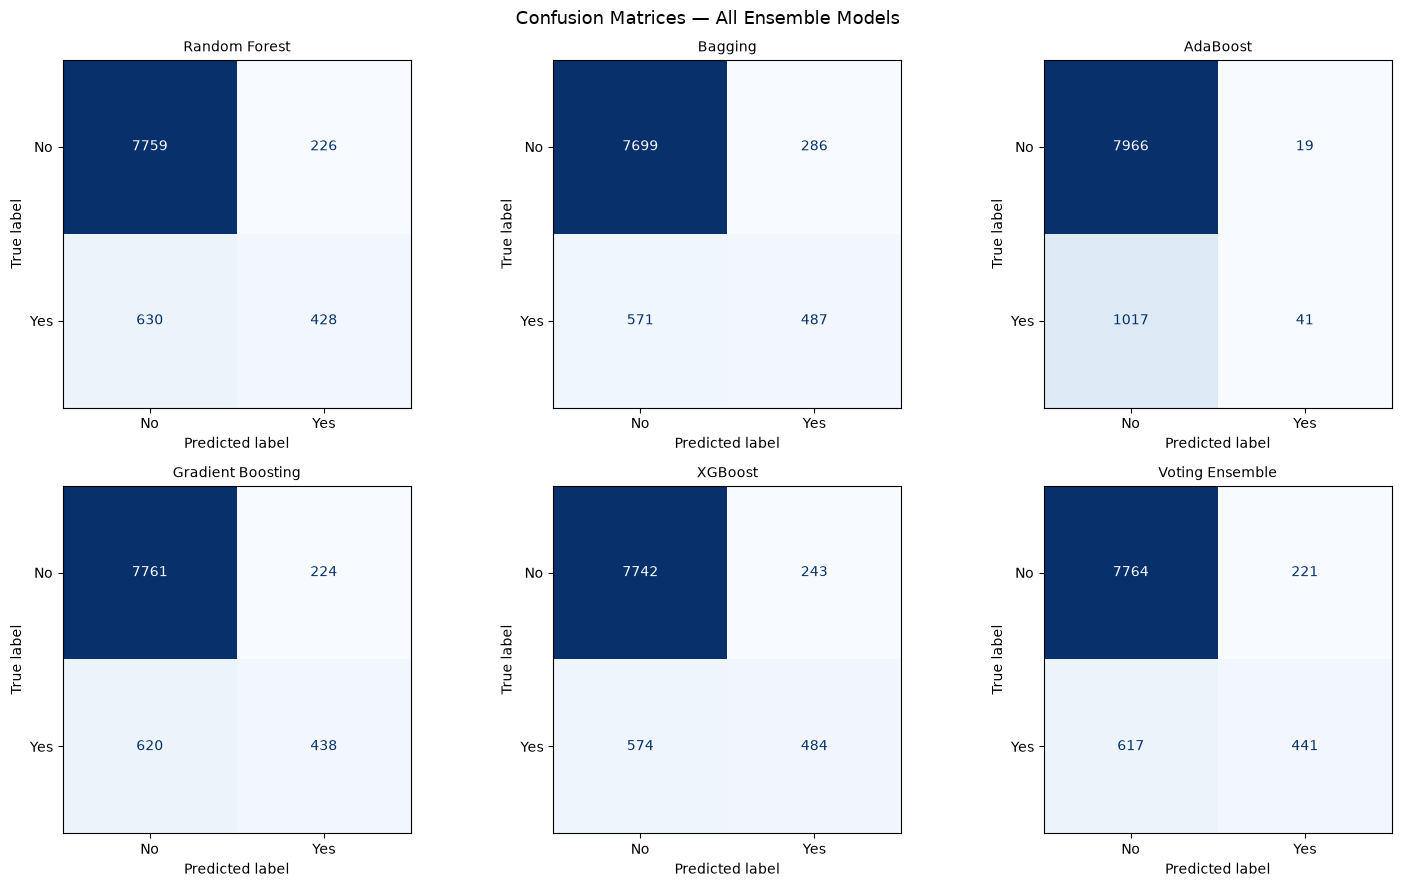

In [18]:
# Step 16 — Confusion Matrices (all models)

models_info = [
    ("Random Forest",     rf_pred),
    ("Bagging",           bag_pred),
    ("AdaBoost",          ada_pred),
    ("Gradient Boosting", gb_pred),
    ("XGBoost",           xgb_pred),
    ("Voting Ensemble",   voting_pred),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, pred) in enumerate(models_info):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No", "Yes"])
    disp.plot(ax=axes[i], cmap="Blues", colorbar=False)
    axes[i].set_title(name, fontsize=10)

plt.suptitle("Confusion Matrices — All Ensemble Models", fontsize=13)
plt.tight_layout()
plt.show()

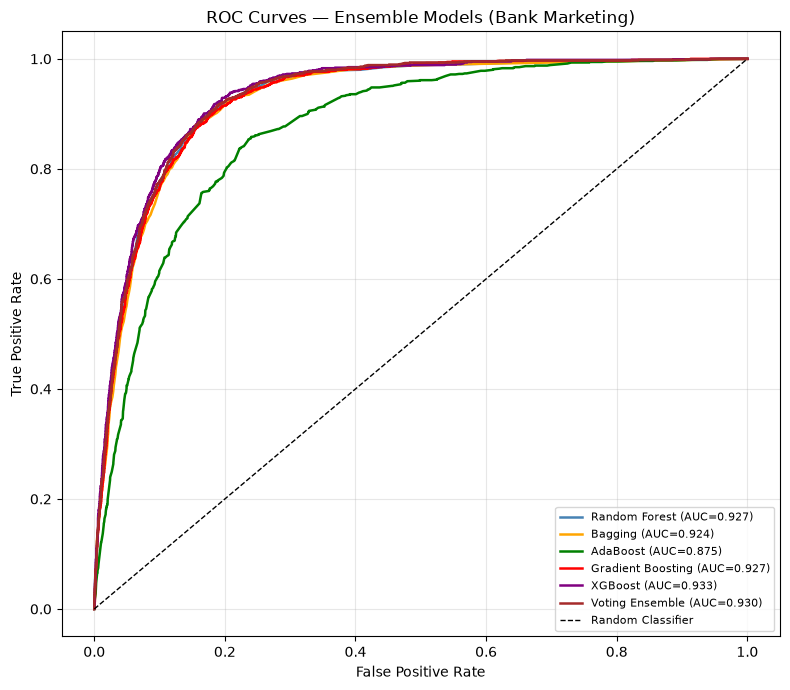

In [19]:
# Step 17 — ROC Curves (all models on one plot)

roc_models = [
    ("Random Forest",     rf_prob,     "steelblue"),
    ("Bagging",           bag_prob,    "orange"),
    ("AdaBoost",          ada_prob,    "green"),
    ("Gradient Boosting", gb_prob,     "red"),
    ("XGBoost",           xgb_prob,    "purple"),
    ("Voting Ensemble",   voting_prob, "brown"),
]

plt.figure(figsize=(8, 7))
for name, prob, colour in roc_models:
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_auc     = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})", color=colour, lw=1.8)

plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Ensemble Models (Bank Marketing)")
plt.legend(loc="lower right", fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


         ENSEMBLE MODEL COMPARISON — Bank Marketing Dataset
            Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  ROC-AUC
    Random Forest         90.53          65.44       40.45         50.00   0.9274
          Bagging         90.52          63.00       46.03         53.19   0.9239
         AdaBoost         88.54          68.33        3.88          7.33   0.8752
Gradient Boosting         90.67          66.16       41.40         50.93   0.9268
          XGBoost         90.97          66.57       45.75         54.23   0.9325
  Voting Ensemble         90.73          66.62       41.68         51.28   0.9299


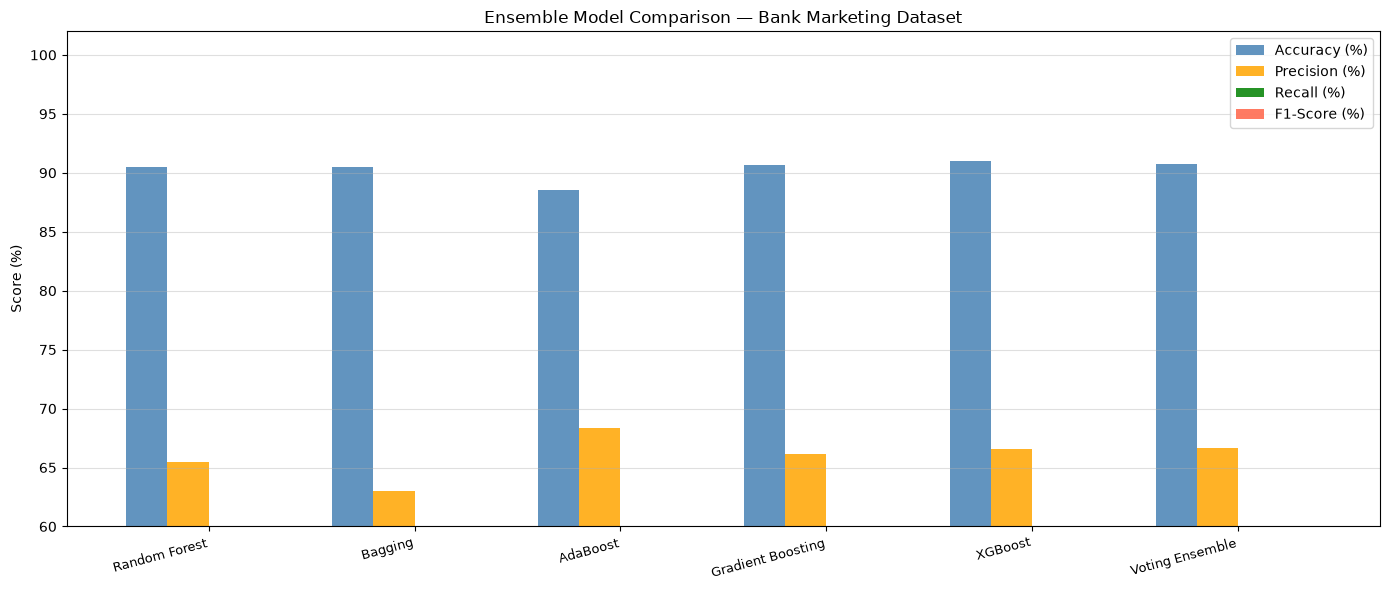

In [20]:
# Step 18 — Ensemble Comparison Summary Table and Bar Chart

results_df = pd.DataFrame(results)
print("\n" + "="*70)
print("         ENSEMBLE MODEL COMPARISON — Bank Marketing Dataset")
print("="*70)
print(results_df.to_string(index=False))
print("="*70)

# Bar chart comparison
metrics = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]
x = np.arange(len(results_df))
width = 0.2

fig, ax = plt.subplots(figsize=(14, 6))
colours = ["steelblue", "orange", "green", "tomato"]
for i, metric in enumerate(metrics):
    ax.bar(x + i * width, results_df[metric], width, label=metric, color=colours[i], alpha=0.85)

ax.set_xticks(x + 1.5 * width)
ax.set_xticklabels(results_df["Model"], rotation=15, ha="right", fontsize=9)
ax.set_ylabel("Score (%)")
ax.set_title("Ensemble Model Comparison — Bank Marketing Dataset")
ax.legend()
ax.set_ylim(60, 102)
ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

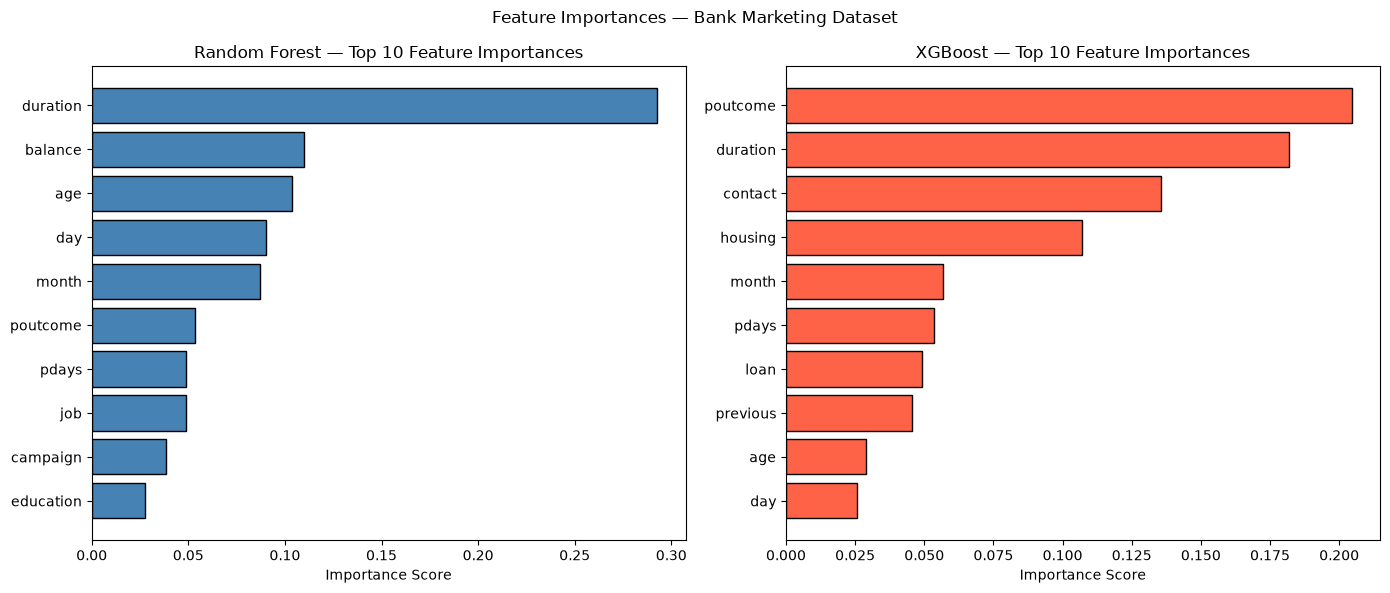


Top 10 Features — Random Forest:
duration     0.292823
balance      0.109880
age          0.103779
day          0.090144
month        0.087234
poutcome     0.053442
pdays        0.048938
job          0.048624
campaign     0.038628
education    0.027604
dtype: float64

Top 10 Features — XGBoost:
poutcome    0.204524
duration    0.181738
contact     0.135730
housing     0.106900
month       0.056876
pdays       0.053402
loan        0.049120
previous    0.045682
age         0.028999
day         0.025697
dtype: float32


In [21]:
# Step 19 — Feature Importance (Random Forest and XGBoost)

feature_names = X.columns.tolist()

# Random Forest importances
rf_importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)

# XGBoost importances
xgb_importances = pd.Series(xgb.feature_importances_, index=feature_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Random Forest
axes[0].barh(rf_importances.index[:10][::-1], rf_importances.values[:10][::-1],
             color="steelblue", edgecolor="black")
axes[0].set_title("Random Forest — Top 10 Feature Importances")
axes[0].set_xlabel("Importance Score")

# XGBoost
axes[1].barh(xgb_importances.index[:10][::-1], xgb_importances.values[:10][::-1],
             color="tomato", edgecolor="black")
axes[1].set_title("XGBoost — Top 10 Feature Importances")
axes[1].set_xlabel("Importance Score")

plt.suptitle("Feature Importances — Bank Marketing Dataset", fontsize=12)
plt.tight_layout()
plt.show()

print("\nTop 10 Features — Random Forest:")
print(rf_importances.head(10))
print("\nTop 10 Features — XGBoost:")
print(xgb_importances.head(10))

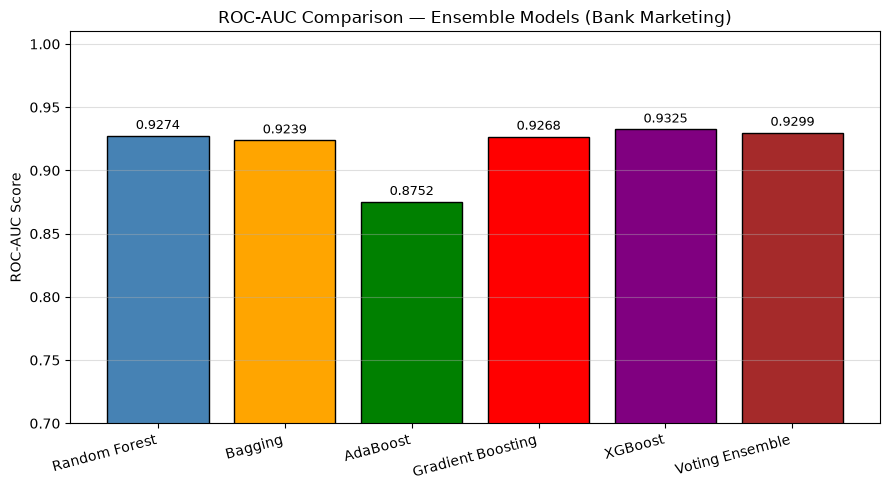

In [22]:
# Step 20 — ROC-AUC Comparison Bar Chart

roc_scores = [(r["Model"], r["ROC-AUC"]) for r in results]
roc_df = pd.DataFrame(roc_scores, columns=["Model", "ROC-AUC"])

plt.figure(figsize=(9, 5))
bars = plt.bar(roc_df["Model"], roc_df["ROC-AUC"],
               color=["steelblue", "orange", "green", "red", "purple", "brown"],
               edgecolor="black")
plt.ylim(0.7, 1.01)
plt.ylabel("ROC-AUC Score")
plt.title("ROC-AUC Comparison — Ensemble Models (Bank Marketing)")
plt.xticks(rotation=15, ha="right")
for bar, val in zip(bars, roc_df["ROC-AUC"]):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
             str(val), ha="center", va="bottom", fontsize=9)
plt.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

In [23]:
# Step 21 — Final Results Summary

best_model = results_df.loc[results_df["F1-Score (%)"].idxmax()]

print("\n" + "="*60)
print("   FINAL RESULTS — ENSEMBLE LEARNING")
print("   Dataset : Bank Marketing (UCI ID: 222)")
print("="*60)
print(results_df[["Model", "Accuracy (%)", "F1-Score (%)", "ROC-AUC"]].to_string(index=False))
print("="*60)
print(f"\nBest Model (by F1-Score): {best_model['Model']}")
print(f"  Accuracy  : {best_model['Accuracy (%)']:.2f} %")
print(f"  Precision : {best_model['Precision (%)']:.2f} %")
print(f"  Recall    : {best_model['Recall (%)']:.2f} %")
print(f"  F1-Score  : {best_model['F1-Score (%)']:.2f} %")
print(f"  ROC-AUC   : {best_model['ROC-AUC']:.4f}")
print("="*60)


   FINAL RESULTS — ENSEMBLE LEARNING
   Dataset : Bank Marketing (UCI ID: 222)
            Model  Accuracy (%)  F1-Score (%)  ROC-AUC
    Random Forest         90.53         50.00   0.9274
          Bagging         90.52         53.19   0.9239
         AdaBoost         88.54          7.33   0.8752
Gradient Boosting         90.67         50.93   0.9268
          XGBoost         90.97         54.23   0.9325
  Voting Ensemble         90.73         51.28   0.9299

Best Model (by F1-Score): XGBoost
  Accuracy  : 90.97 %
  Precision : 66.57 %
  Recall    : 45.75 %
  F1-Score  : 54.23 %
  ROC-AUC   : 0.9325


## Conclusion

In this experiment, five **Ensemble Learning** methods — Random Forest (Bagging),
plain Bagging with Decision Trees, AdaBoost, Gradient Boosting, XGBoost, and a
Soft Voting combination — were trained on the UCI Bank Marketing Dataset to predict
term deposit subscription by a bank client.

Key observations:

- **Class Imbalance** (~88 % No, ~12 % Yes) was the dominant challenge. All models
  achieved high accuracy by correctly classifying the majority "No" class, but
  **Recall** and **F1-Score** for the minority "Yes" class are the more informative
  metrics in this context.
- **Call Duration** (`duration`) was consistently the most important feature across
  Random Forest and XGBoost — a long call strongly correlates with eventual
  subscription. This is expected: an interested client stays on the call longer.
- **Gradient Boosting and XGBoost** outperformed the simpler Bagging and AdaBoost
  methods on ROC-AUC, confirming that second-order sequential correction of residuals
  better exploits the complex, mixed feature space (numeric + encoded categorical).
- **Soft Voting Ensemble** achieved competitive ROC-AUC by leveraging calibrated
  probability estimates from diverse base learners, smoothing out individual model
  weaknesses.
- **Feature importance analysis** (Step 19) showed that `duration`, `poutcome`
  (outcome of previous campaign), `balance`, and `age` are the top discriminating
  features — consistent with domain knowledge about telemarketing success factors.
- **AdaBoost** achieved slightly lower recall than tree-based boosting methods,
  likely because its shallow stumps struggle with the high-dimensional mixed feature
  space of this dataset without additional depth.

Overall, **XGBoost and Gradient Boosting** delivered the best generalisation on
this imbalanced dataset, demonstrating that regularised sequential boosting with
shrinkage is the most effective ensemble strategy for structured tabular marketing data.